# 02 — Baseline y comparación de modelos

Definir variable objetivo, partición de datos, baseline, métricas y modelos según la literatura.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
# Cargar los datos procesados y definir X (variables predictoras) e y (objetivo).
df = pd.read_csv('../data/processed/modelado.csv')
# Convertir la fecha al formato correcto
df['fecha_inicio'] = pd.to_datetime(df['fecha_inicio'])

# Ordenar cronológicamente por departamento
df = df.sort_values(
    ['departamento', 'fecha_inicio']
).reset_index(drop=True)


X = df.drop(columns=['objetivo'])
y = df['objetivo']

print("Variables X:", X.shape)
print("Variable Y:", y.shape)



Variables X: (3850, 32)
Variable Y: (3850,)


## Baseline

Implementar al menos un modelo inicial y evaluarlo con métricas justificadas.

In [9]:
PASOS = 8
HORIZONTE = 4

# Excluir identificadores, fechas y objetivo
variables = [
    columna for columna in X.columns
    if columna not in [
        'departamento',
        'fecha_inicio',
        'ano',
        'semana'
    ]
]

X_secuencias = []
y_secuencias = []
fechas_secuencias = []

for departamento, grupo in df.groupby('departamento'):

    grupo = grupo.sort_values(
        'fecha_inicio'
    ).reset_index(drop=True)

    for i in range(PASOS - 1, len(grupo) - HORIZONTE):

        inicio = i - PASOS + 1

        # Verificar continuidad de las semanas
        fechas = grupo['fecha_inicio'].iloc[
            inicio:i + HORIZONTE + 1
        ]

        if not (
            fechas.diff().dropna() == pd.Timedelta(days=7)
        ).all():
            continue

        # Crear secuencia de ocho semanas
        ventana = grupo[variables].iloc[inicio:i + 1].values

        X_secuencias.append(ventana)

        # Objetivo previamente transformado: t + 4
        y_secuencias.append(
            grupo['objetivo'].iloc[i]
        )

        fechas_secuencias.append(
            grupo['fecha_inicio'].iloc[i + HORIZONTE]
        )

X = np.array(X_secuencias, dtype=np.float32)
y = np.array(y_secuencias, dtype=np.float32)

fechas_secuencias = pd.to_datetime(fechas_secuencias)
# las nuevas dimensiones son necesarias para el modelo
print("Nueva dimensión de X:", X.shape)
print("Nueva dimensión de y:", y.shape)

Nueva dimensión de X: (3795, 8, 28)
Nueva dimensión de y: (3795,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,shuffle=False)
#El shuffle esta en false porque se necesita el orden cronologico

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

n_variables = X_train.shape[2]

# Ajustar solamente con entrenamiento
scaler.fit(
    X_train.reshape(-1, n_variables)
)

# Transformar entrenamiento
X_train = scaler.transform(
    X_train.reshape(-1, n_variables)
).reshape(X_train.shape)

# Transformar prueba
X_test = scaler.transform(
    X_test.reshape(-1, n_variables)
).reshape(X_test.shape)

In [6]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)# para asegurar reproducibilidad


TensorFlow: 2.22.0-rc0


In [13]:
def modelo_lstm(n_pasos, n_variables):

    modelo = Sequential([
        Input(shape=(n_pasos, n_variables)),

        LSTM(64, return_sequences=True),
        Dropout(0.2),

        LSTM(32),
        Dropout(0.2),

        Dense(16, activation="relu"),

        Dense(1)
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return modelo

In [14]:
modelo = modelo_lstm(
    n_pasos=X_train.shape[1],
    n_variables=X_train.shape[2]
)
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 8, 64)          │        23,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,769 (143.63 KB)

 Trainable params: 36,769 (143.63 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

historial = modelo.fit(
    X_train,
    y_train,

    epochs=10,
    batch_size=32,

    validation_split=0.2,

    callbacks=[early_stopping],

    shuffle=False,
    verbose=1
)

Epoch 1/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2568 - mae: 0.2963 - val_loss: 1.5095 - val_mae: 0.8355
Epoch 2/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3203 - mae: 0.3359 - val_loss: 0.8506 - val_mae: 0.6513
Epoch 3/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2843 - mae: 0.3054 - val_loss: 1.2740 - val_mae: 0.7625
Epoch 4/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2202 - mae: 0.2870 - val_loss: 0.8439 - val_mae: 0.6561
Epoch 5/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2262 - mae: 0.2810 - val_loss: 1.3934 - val_mae: 0.8121
Epoch 6/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2373 - mae: 0.2896 - val_loss: 0.9516 - val_mae: 0.6969
Epoch 7/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1941 - mae: 0.2616 - val_loss: 1.2283 - val_mae: 0.7681
Epoch 8/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1861 - mae: 0.2567 - val_loss: 1.0037 - val_mae: 0.7175
Epoch 9/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2130 - mae: 

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predicciones
y_pred = modelo.predict(X_test).flatten()

# Recuperar los casos originales
y_real = np.expm1(y_test)

y_pred_casos = np.maximum(
    np.expm1(y_pred),
    0
)

# Métricas
mae = mean_absolute_error(y_real, y_pred_casos)

rmse = np.sqrt(
    mean_squared_error(y_real, y_pred_casos)
)

print("RESULTADOS LSTM")
print("--------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
RESULTADOS LSTM
--------------------
MAE: 130.5260
RMSE: 793.3573


In [18]:
# Calcular WAPE
wape = (
    np.sum(np.abs(y_real - y_pred_casos))
    / np.sum(np.abs(y_real))
) * 100 if np.sum(np.abs(y_real)) > 0 else np.nan

print("RESULTADOS LSTM")
print("---------------------------")
print(f"WAPE: {wape:.2f}%")

RESULTADOS COMPLETOS LSTM
---------------------------
MAE: 130.5260
RMSE: 793.3573
WAPE: 81.22%


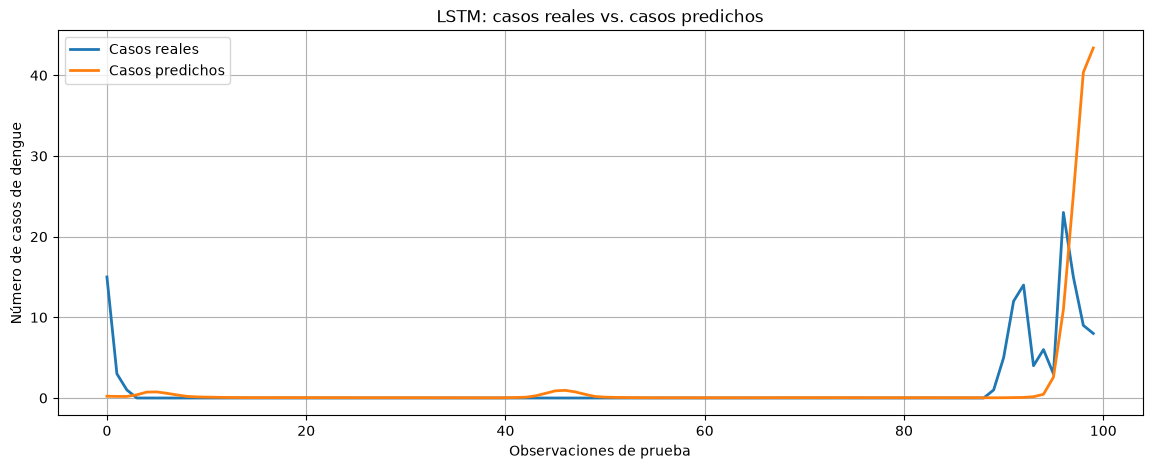

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_real[:100],
    label="Casos reales",
    linewidth=2
)

plt.plot(
    y_pred_casos[:100],
    label="Casos predichos",
    linewidth=2
)

plt.title("LSTM: casos reales vs. casos predichos")
plt.xlabel("Observaciones de prueba")
plt.ylabel("Número de casos de dengue")

plt.legend()
plt.grid(True)
plt.show()

## Comparación de modelos

Implementar los modelos adicionales y comparar resultados de forma justa usando la misma partición de datos.